**GDGC Weak 2 Task  Matplotlib and Seaborn Assignment (Visualization)**

#Task1 Line plot

**Importing Libraries and loading dataset**

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
flights = sns.load_dataset("flights")

**Viewing first 5 records of flights dataset**

In [2]:
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


**Getting the 1955 year record and Drawing  Line Plot**

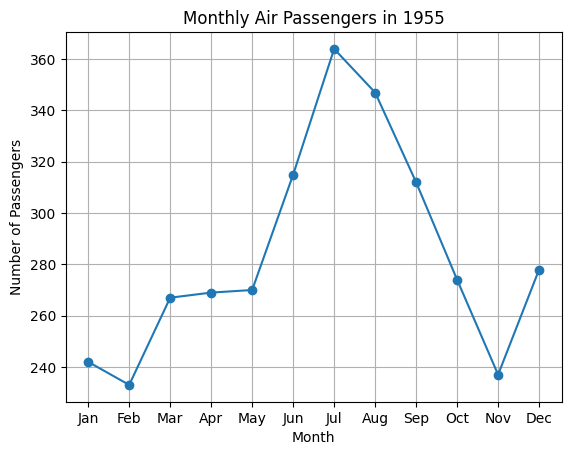

In [3]:
year_data = flights[flights["year"] == 1955]
plt.plot(year_data["month"], year_data["passengers"],marker="o")
plt.title("Monthly Air Passengers in 1955")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.grid(True)
plt.show()

****Insights****

The number of passengers generally increased during 1955 year. Initially after decline the trend start increasing from Feburary to March, after little stability from March to May,again starting to rise and then  it say its peak in July . Then a steeper decline , Lowest in november and in January slightly rise to December and sets to a  higher  position than January.

#Task 2 Bar Chart

**Load Dataset**

In [4]:
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


**Getting Average bill of each day**

In [5]:
avg_bill = tips.groupby("day")["total_bill"].mean()
print(avg_bill)

day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64


/tmp/ipykernel_787/2895680131.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_bill = tips.groupby("day")["total_bill"].mean()


**Creating Custom Colors and drawing bar chart with values of each category on top**

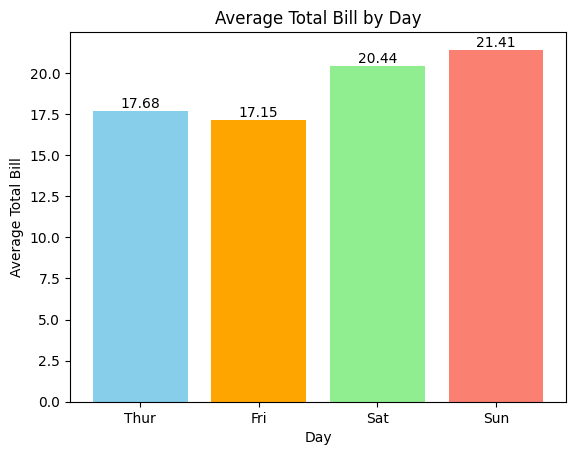

In [6]:
# Custom colors
colors = ["skyblue", "orange", "lightgreen", "salmon"]

# Create bar chart
bars = plt.bar(
    avg_bill.index,
    avg_bill.values,
    color=colors
)

# Title and labels
plt.title("Average Total Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Total Bill")

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.show()

****Insights****

The plot shows that friday has the lowest average bill, while thursday has a little higher average then friday. Saturday has significant higher average daily bill while sunday remains on top by having highest average total bill means that more sale on sunday

#Task 3 Horizontal bar Chart

**Importing Dataset and Drawing Horizontal Bar Chart**

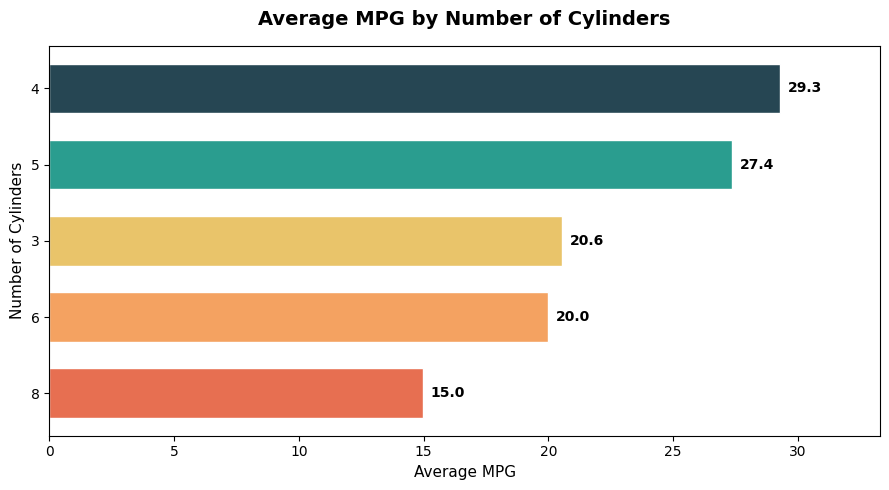

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
mpg = sns.load_dataset("mpg")

# Calculate average MPG by cylinders
avg_mpg = mpg.groupby("cylinders")["mpg"].mean()

# Sort from highest to lowest
avg_mpg = avg_mpg.sort_values(ascending=False)

# Your custom colors
colors = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]

# Create figure
plt.figure(figsize=(9, 5))

# Create horizontal bar chart
bars = plt.barh(
    avg_mpg.index.astype(str),
    avg_mpg.values,
    color=colors[:len(avg_mpg)],
    edgecolor="white",
    height=0.65
)

# Put highest MPG at the top
plt.gca().invert_yaxis()

# Add value labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# Title and axis labels
plt.title(
    "Average MPG by Number of Cylinders",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Average MPG", fontsize=11)
plt.ylabel("Number of Cylinders", fontsize=11)


# Give some space for value labels
plt.xlim(0, avg_mpg.max() + 4)

plt.tight_layout()
plt.show()

****Insights****

This MPG dataset contains ifromation about different cars, thier cylinders and average MPG along with other column. In this chart we have observed the 4 cylinders has highest average MPG means they are more petrol efficient. The 3 engines has surprisingly low average then 4 and 5 , 5 has second  highest average Mpg  . while 6 and 8 cylinders are among the lowest mpg specially 8 is the lowest among all

#Task 4 Histogram

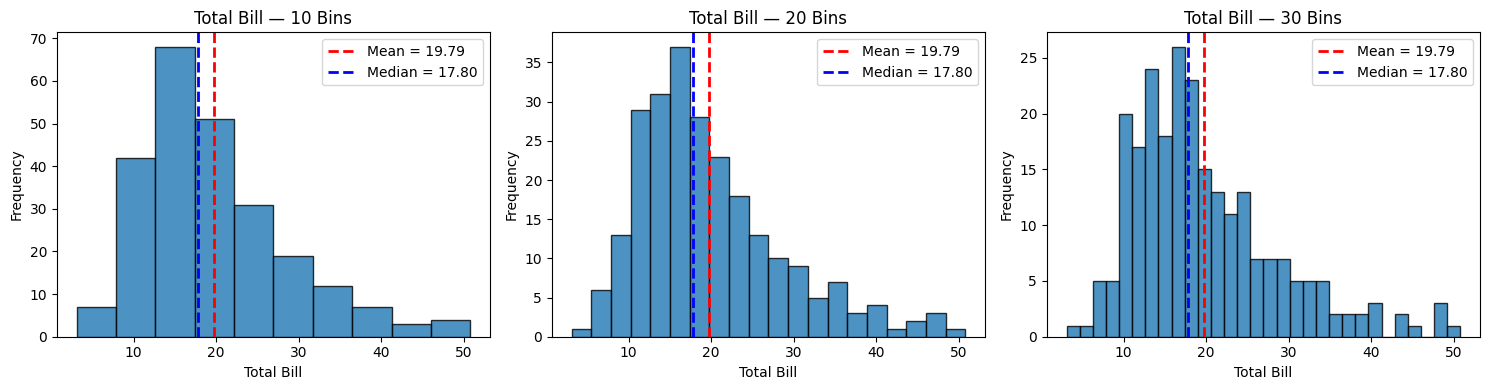

In [8]:

import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
tips = sns.load_dataset("tips")

# Calculate mean and median
mean_bill = tips["total_bill"].mean()
median_bill = tips["total_bill"].median()

# Create 3 side-by-side subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Different bin sizes
bin_sizes = [10, 20, 30]

for ax, bins in zip(axes, bin_sizes):

    # Create histogram
    ax.hist(
        tips["total_bill"],
        bins=bins,
        edgecolor="black",
        alpha=0.8
    )

    # Mean line
    ax.axvline(
        mean_bill,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean_bill:.2f}"
    )

    # Median line
    ax.axvline(
        median_bill,
        color="blue",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median_bill:.2f}"
    )

    # Title and labels
    ax.set_title(f"Total Bill — {bins} Bins")
    ax.set_xlabel("Total Bill")
    ax.set_ylabel("Frequency")

    # Legend
    ax.legend()

# Overall layout
plt.tight_layout()
plt.show()

****Insights****

 There is approximately little difference between mean and median around 2 dollars approximately which suggest that average bill mostly lies between 15 to 20 range.
 We can see that first grapsh with 20 bins are showing less details as compared to 20 bins graph which is showing significant details , but the 30 bins graph has became too noisy means it show too much detail which makes it difficult to process.

#Task 5 Scatter plot

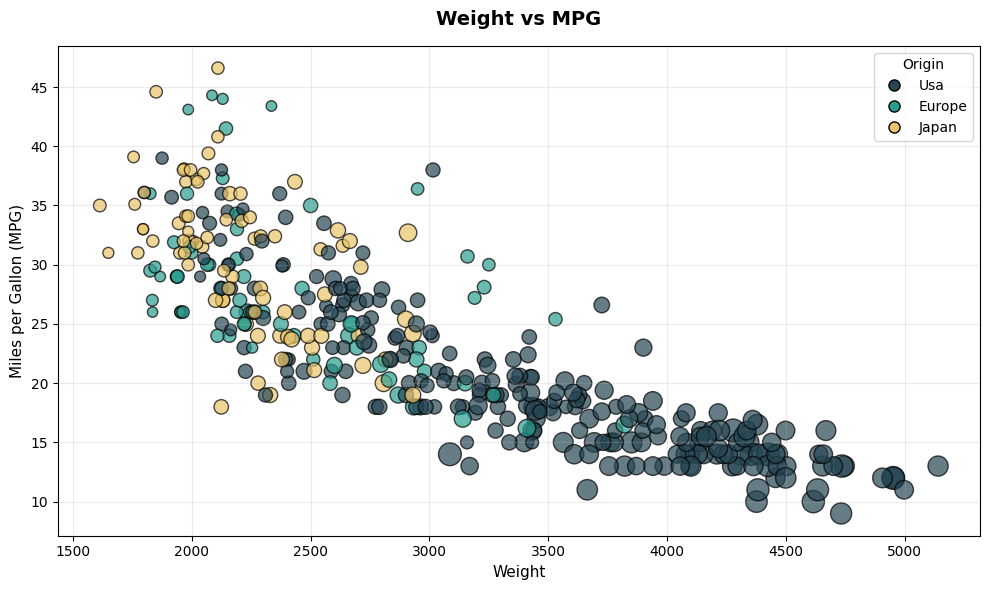

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Load dataset
mpg = sns.load_dataset("mpg")

# Remove rows with missing values
scatter_data = mpg.dropna(
    subset=["weight", "mpg", "origin", "horsepower"]
)

# Custom colors for origin
origin_colors = {
    "usa": "#264653",
    "europe": "#2A9D8F",
    "japan": "#E9C46A"
}

# Map colors to each observation
colors = scatter_data["origin"].map(origin_colors)

# Scale horsepower for point size
sizes = scatter_data["horsepower"] * 1.2

# Create figure
plt.figure(figsize=(10, 6))

# Create scatter plot
plt.scatter(
    scatter_data["weight"],
    scatter_data["mpg"],
    c=colors,
    s=sizes,
    alpha=0.7,
    edgecolor="black"
)

# Title and labels
plt.title(
    "Weight vs MPG",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Weight", fontsize=11)
plt.ylabel("Miles per Gallon (MPG)", fontsize=11)

# Create custom legend for origin
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label=origin.title(),
        markerfacecolor=color,
        markeredgecolor="black",
        markersize=8
    )
    for origin, color in origin_colors.items()
]

plt.legend(
    handles=legend_elements,
    title="Origin"
)

# Add grid
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

****Insights****

 From this scatter grapsh it can be noted that the relation between the weight and MPG is negative. I.e the more the weight is the less the MPG. by looking at size of circles, the the hight weigth specially the highest one has stronges horsepower engines. From colors it can be seen that USA engines has more weight and horsepower while Japan Europe has lower wieights but more MPG.

#Task 6 Pie or donut chart

**PIE  Chart**

smoker
No     151
Yes     93
Name: count, dtype: int64


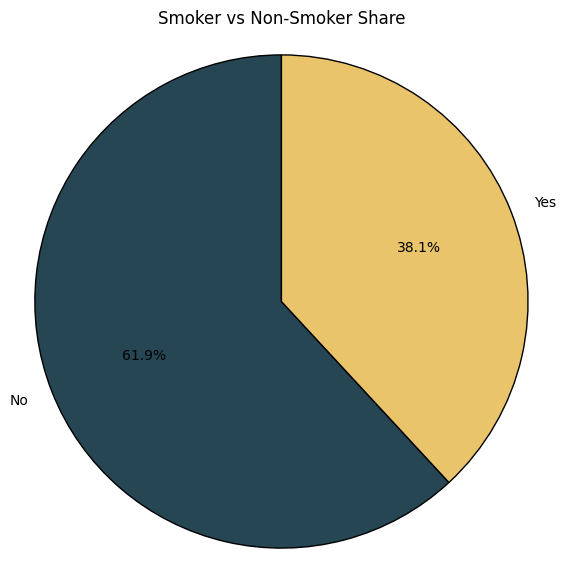

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")
smoker_counts = tips["smoker"].value_counts()

print(smoker_counts)
colors = ["#264653", "#E9C46A"]

plt.figure(figsize=(7, 7))

plt.pie(
    smoker_counts.values,
    labels=smoker_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "black"}
)

plt.title("Smoker vs Non-Smoker Share")

plt.axis("equal")

plt.show()

**Donut Chart**

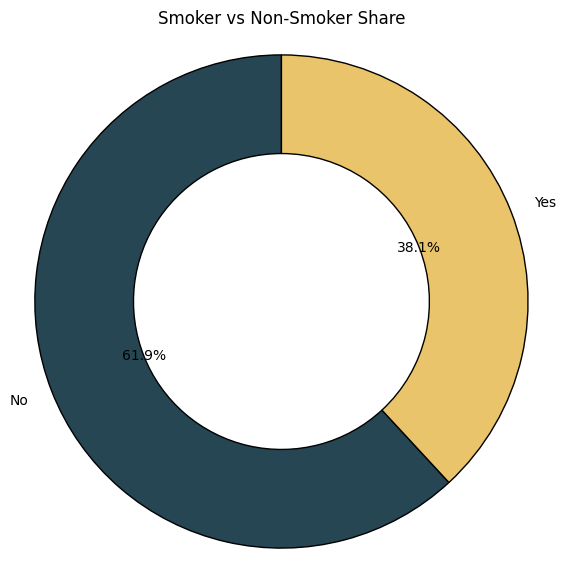

In [11]:
colors = ["#264653", "#E9C46A"]

plt.figure(figsize=(7, 7))

plt.pie(
    smoker_counts.values,
    labels=smoker_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={
        "width": 0.4,
        "edgecolor": "black"
    }
)

plt.title("Smoker vs Non-Smoker Share")

plt.axis("equal")

plt.show()

****Insights****

 From   Charts it is shows that 38.1 % people are smokers while 61.9 percent people are non smokers

#Tas 7 Mini dashboard

/tmp/ipykernel_787/2423099368.py:37: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_bill = tips.groupby("day")["total_bill"].mean()


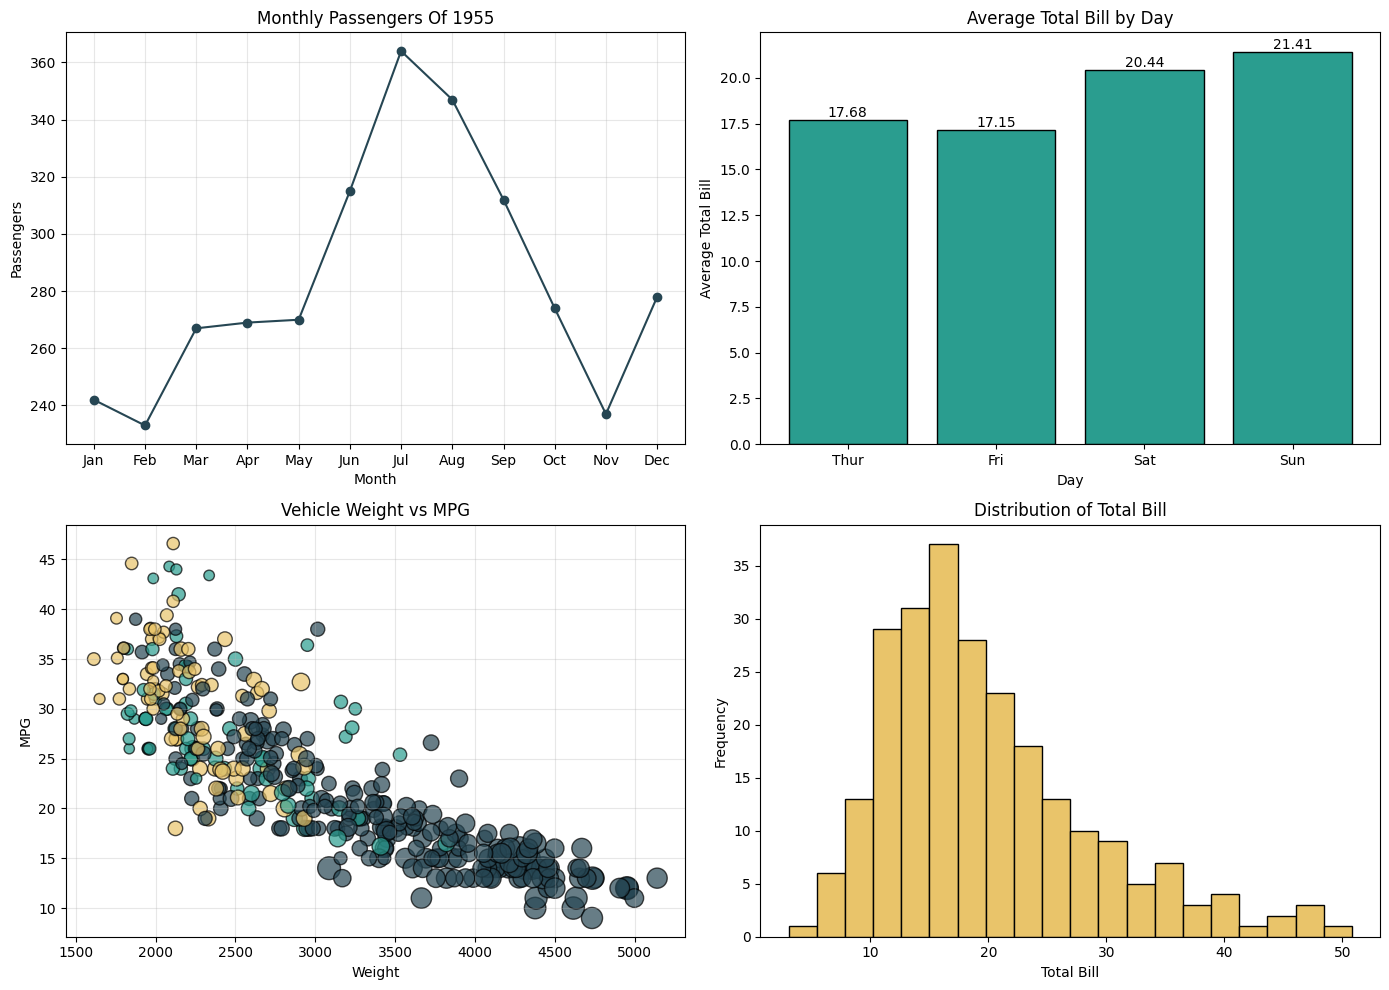

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load datasets
flights = sns.load_dataset("flights")
tips = sns.load_dataset("tips")
mpg = sns.load_dataset("mpg")


# Create 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))


# -------------------------
# 1. Line Plot
# -------------------------

year_data = flights[flights["year"] == 1955]

axes[0, 0].plot(
    year_data["month"],
    year_data["passengers"],
    marker="o",
    color="#264653"
)

axes[0, 0].set_title("Monthly Passengers Of 1955")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Passengers")
axes[0, 0].grid(True, alpha=0.3)


# -------------------------
# 2. Bar Chart
# -------------------------

avg_bill = tips.groupby("day")["total_bill"].mean()

bars = axes[0, 1].bar(
    avg_bill.index,
    avg_bill.values,
    color="#2A9D8F",
    edgecolor="black"
)

axes[0, 1].set_title("Average Total Bill by Day")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Average Total Bill")

for bar in bars:
    height = bar.get_height()

    axes[0, 1].text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

# -------------------------
# 3. Scatter Plot
# -------------------------

scatter_data = mpg.dropna(
    subset=["weight", "mpg", "horsepower", "origin"]
)

origin_colors = {
    "usa": "#264653",
    "europe": "#2A9D8F",
    "japan": "#E9C46A"
}

colors = scatter_data["origin"].map(origin_colors)

axes[1, 0].scatter(
    scatter_data["weight"],
    scatter_data["mpg"],
    s=scatter_data["horsepower"] * 1.2,
    c=colors,
    alpha=0.7,
    edgecolor="black"
)

axes[1, 0].set_title("Vehicle Weight vs MPG")
axes[1, 0].set_xlabel("Weight")
axes[1, 0].set_ylabel("MPG")
axes[1, 0].grid(True, alpha=0.3)
# -------------------------
# 4. Histogram
# -------------------------

axes[1, 1].hist(
    tips["total_bill"],
    bins=20,
    color="#E9C46A",
    edgecolor="black"
)

axes[1, 1].set_title("Distribution of Total Bill")
axes[1, 1].set_xlabel("Total Bill")
axes[1, 1].set_ylabel("Frequency")


# Layout
plt.tight_layout()

# Save dashboard
plt.savefig(
    "matplotlib_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

****Insights****

 The dashboards shows different aspects of different datasets at once which we can anlyze at once easily. On one chart we can see the Montly passengers of year 1955, on second chart average total bill by day, the third chart shows the relation between weight and MPG while last chart shows the distribution of total bill.

#Part 2: Seaborn Tasks

# Task 1 Countplot

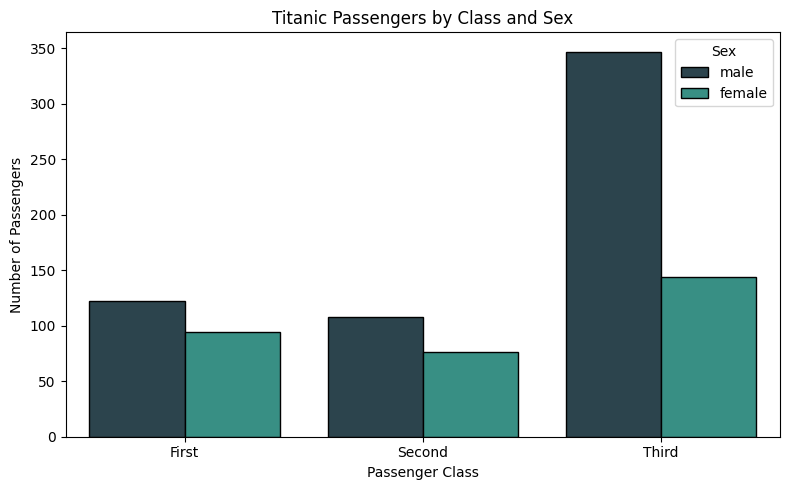

In [13]:

import seaborn as sns
import matplotlib.pyplot as plt

# Custom color palette
colors = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]

# Load dataset
titanic = sns.load_dataset("titanic")

# Set figure size
plt.figure(figsize=(8, 5))

# Create count plot
sns.countplot(
    data=titanic,
    x="class",
    hue="sex",
    palette=colors[:2],
    edgecolor="black"
)

# Titles and labels
plt.title("Titanic Passengers by Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.legend(title="Sex")
plt.tight_layout()
plt.show()

****Insights****

 From the count plot it is shown that in first and second class Male passengers are little  higher than femals passengers. while in Third class the male passengers are much more than female passengers even more than half of them.

# Task 2 Histogram with KDE

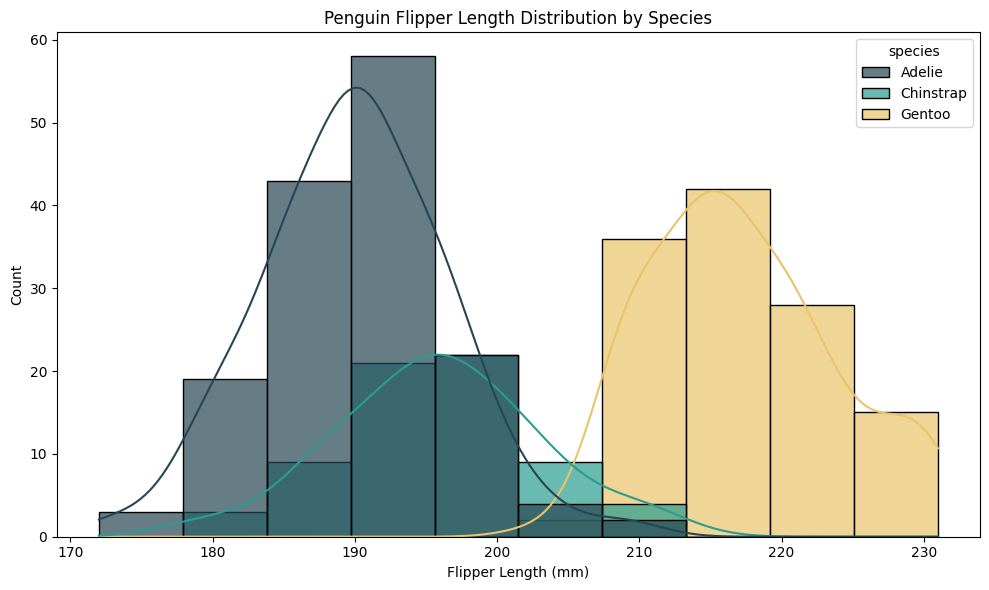

In [14]:

import seaborn as sns
import matplotlib.pyplot as plt

# Custom color palette
colors = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]

# Load dataset
penguins = sns.load_dataset("penguins")

# Set figure size
plt.figure(figsize=(10, 6))

# Histogram with KDE
sns.histplot(
    data=penguins,
    x="flipper_length_mm",
    hue="species",
    kde=True,
    palette=colors[:3],
    edgecolor="black",
    alpha=0.7,
    multiple="layer"
)

# Titles and labels
plt.title("Penguin Flipper Length Distribution by Species")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

****Insights****

This histograms shows that Adelie specie    flipper length mostly ranges between 170 to 210, and the mean lies around 190. While Chinstrap flipper ranges from 180 to 210 with mean aroun 195. The Gentoo has longest flipper length of mean around 215.

# Task 3 Box vs violin

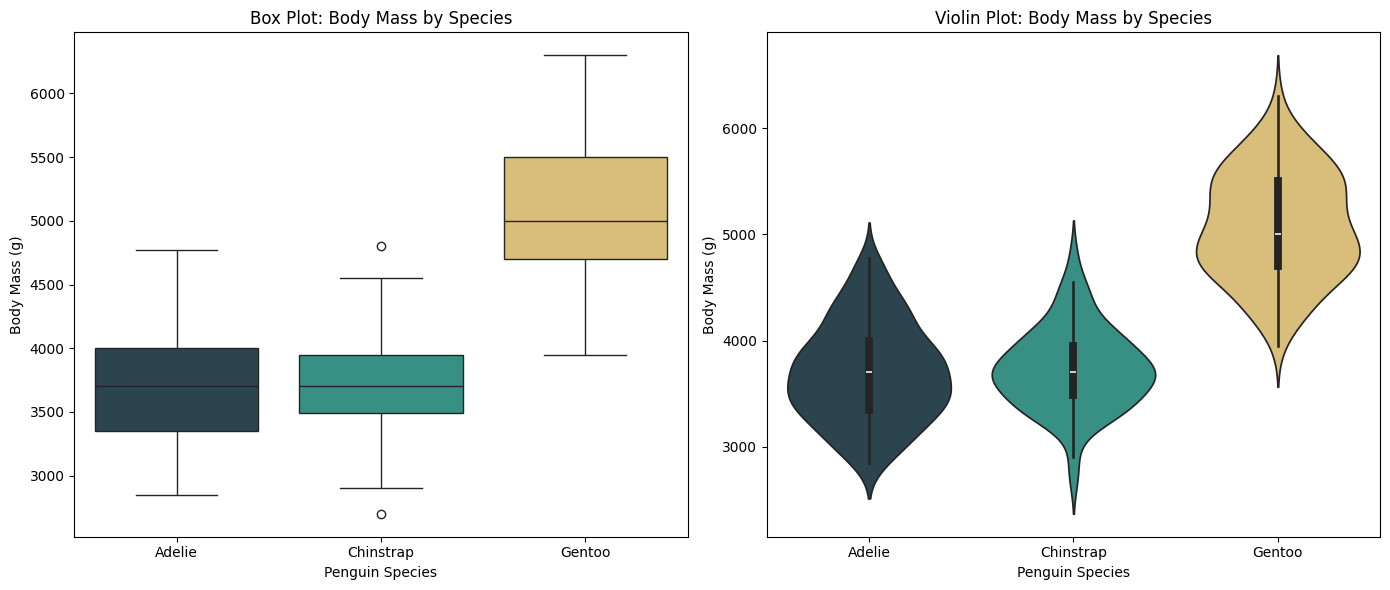

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Custom color palette
colors = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]

# Load dataset
penguins = sns.load_dataset("penguins")

# Remove missing values
penguins_clean = penguins.dropna(
    subset=["species", "body_mass_g"]
)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Box Plot
sns.boxplot(
    data=penguins_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    palette=colors[:3],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Box Plot: Body Mass by Species")
axes[0].set_xlabel("Penguin Species")
axes[0].set_ylabel("Body Mass (g)")

# Violin Plot
sns.violinplot(
    data=penguins_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    palette=colors[:3],
    legend=False,
    inner="box",
    ax=axes[1]
)

axes[1].set_title("Violin Plot: Body Mass by Species")
axes[1].set_xlabel("Penguin Species")
axes[1].set_ylabel("Body Mass (g)")

plt.tight_layout()
plt.show()

****Insights****

In the box plot Chinstrap has lowest distribution and lowest interquartile range of data with some outliers, Adelie data ranges from below 3thousand to less than 5000g. while Gentoo has higher side range of  mass distribution with largest interquartile range.
From the Voilon plot we can see that on the middle of the all plots the density is usually higher. While Gentoo has most enven distribution of data.
Box  VS Voilon: The voilon plot gave us more insights by showing us distribution of data along with box plots quartile ragnes.

# Task 4 Scatterplot

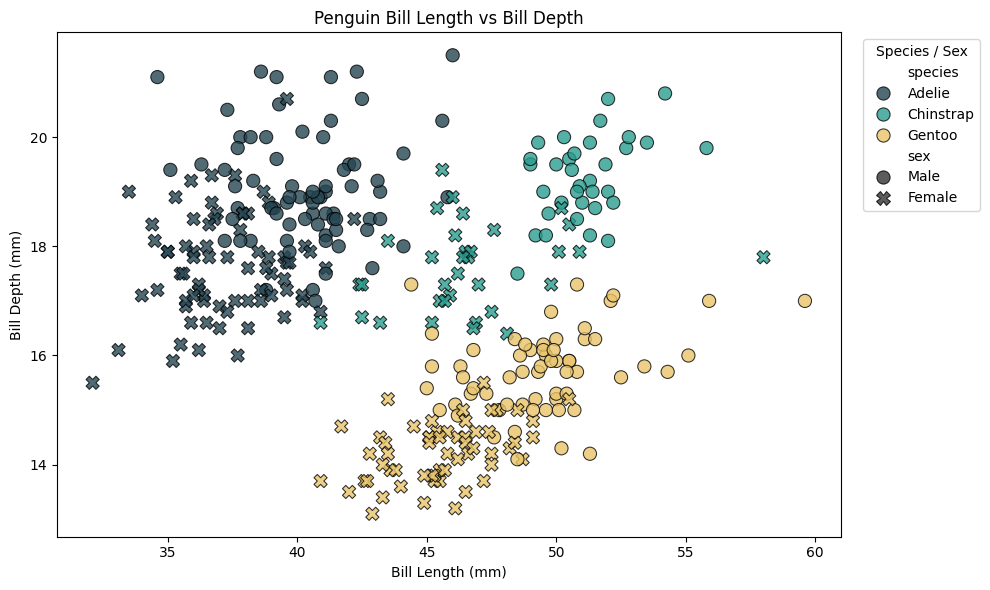

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Custom color palette
colors = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]

# Load dataset
penguins = sns.load_dataset("penguins")

# Remove missing values
penguins_clean = penguins.dropna(
    subset=["bill_length_mm", "bill_depth_mm", "species", "sex"]
)

# Create figure
plt.figure(figsize=(10, 6))

# Scatter plot
sns.scatterplot(
    data=penguins_clean,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    style="sex",
    palette=colors[:3],
    s=90,
    edgecolor="black",
    alpha=0.8
)

# Titles and labels
plt.title("Penguin Bill Length vs Bill Depth")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")

# Legend
plt.legend(
    title="Species / Sex",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

****Insights****

From this scatter chart it can be seen that Male species has more depths on higher bill lengths.
And there is no direct relationship observed between bill length and bill depth. Usually on higher length they have same bill length. except for some male species that has more depth on higher length.

# Task 5 Heatmap

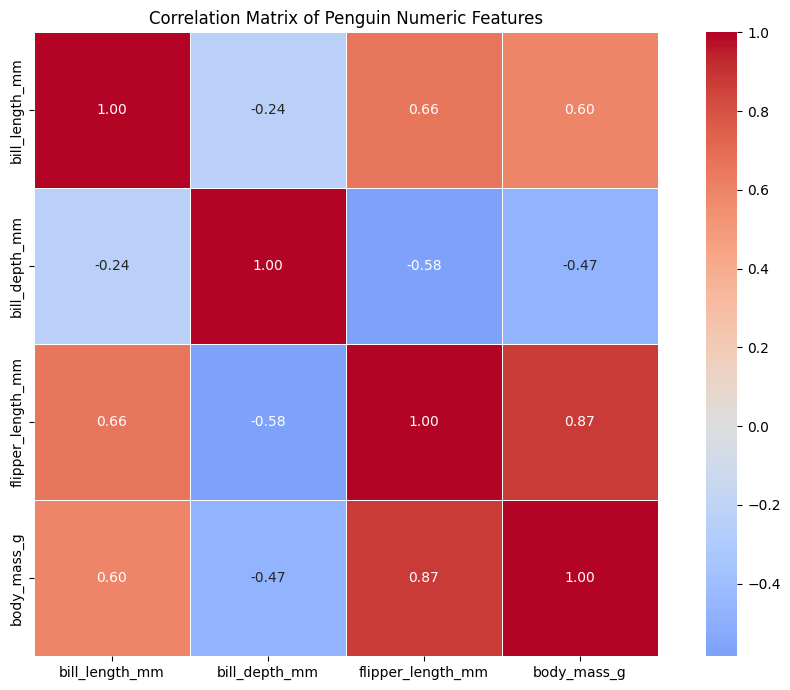

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

colors = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]

penguins = sns.load_dataset("penguins")

# Select only numeric columns
numeric_data = penguins.select_dtypes(include="number")

# Create correlation matrix
corr = numeric_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix of Penguin Numeric Features")
plt.tight_layout()
plt.show()

****Insights****

The heatmap shows that bill lenght  has  positive corelation with flipper length and body mass while negative with bill depth.
The bill depth has negative corelation with all others.
The flipper length has postive corelation with   body mass and bill length     and negative with bill depth.
The body mass has postive corelation with bill length and flipper length      and negative with bill depth.

# Task 6 Pairplot

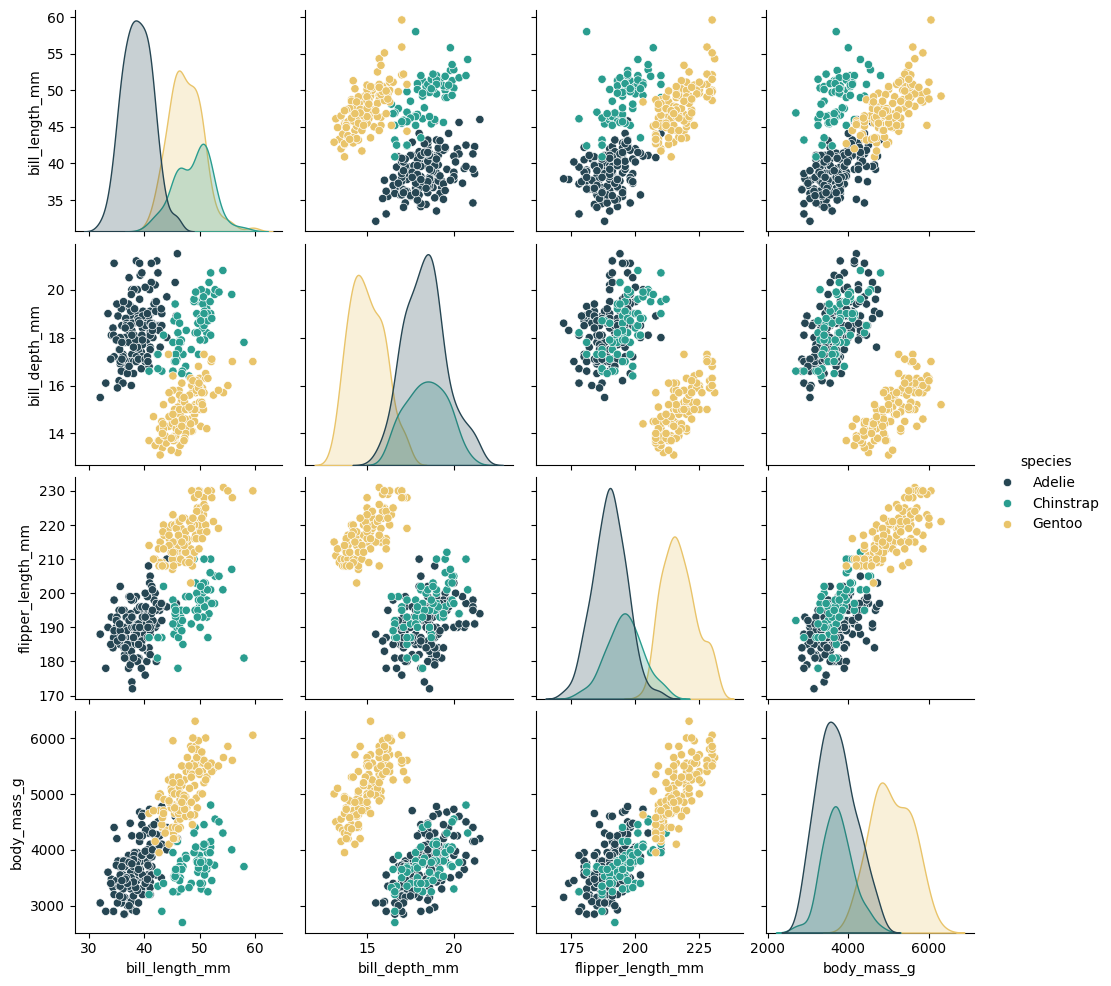

In [19]:

import seaborn as sns
import matplotlib.pyplot as plt

colors = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]

penguins = sns.load_dataset("penguins")

penguins_clean = penguins.dropna(
    subset=[
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g",
        "species"
    ]
)

sns.pairplot(
    data=penguins_clean,
    vars=[
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g"
    ],
    hue="species",
    palette=colors[:3]
)

plt.show()

****Insights****

 Insight 1: Flipper length and body mass show a strong positive relationship, especially for Gentoo penguins.

Insight 2: The three penguin species form relatively distinct groups based on their bill and body measurements.

Insight 3: Gentoo penguins generally have larger flipper lengths and higher body masses compared with Adelie and Chinstrap penguins.

# Task 7 lmplot / FacetGrid

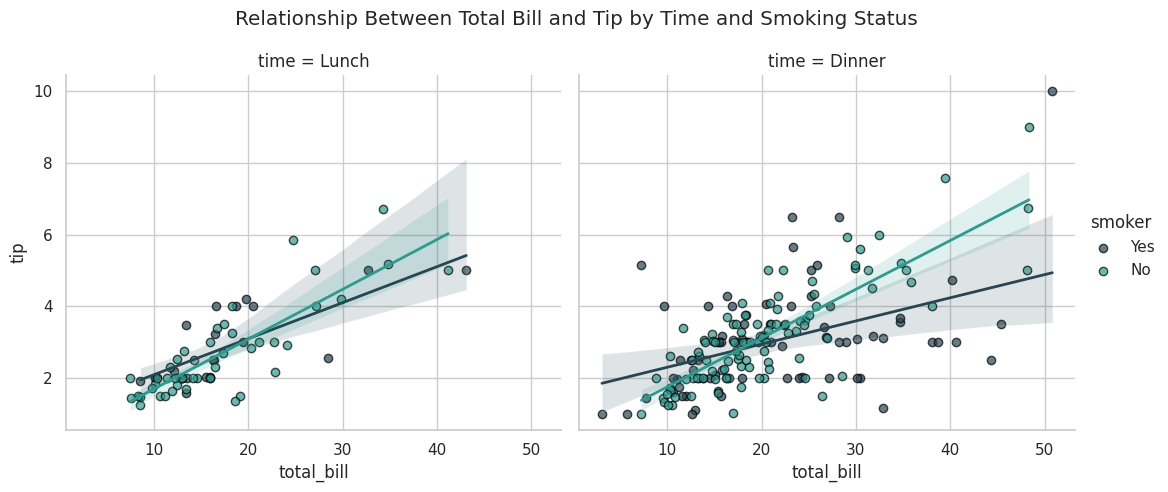

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

colors = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261", "#E76F51"]

# Load dataset
tips = sns.load_dataset("tips")

# Set custom theme
sns.set_theme(
    style="whitegrid",
    palette=colors
)

# Create regression plots
sns.lmplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="smoker",
    col="time",
    palette=colors[:2],
    height=5,
    aspect=1.1,
    scatter_kws={"alpha": 0.7, "edgecolor": "black"},
    line_kws={"linewidth": 2}
)

plt.subplots_adjust(top=0.85)
plt.suptitle("Relationship Between Total Bill and Tip by Time and Smoking Status")

plt.show()

****Insights****

Total bill and tip generally show a positive relationship, meaning that larger bills tend to be associated with larger tips. The regression lines allow us to compare this trend between smokers and non smokers during lunch and dinner. And from regression lines it can be seen that for larger total bill non smokers gave more tips while for the smaller bills the smokers gave more tips.